# WSI classification: frozen encoders and two pooling classifiers

Compare **original UNI (histopathology)**, **DINO ViT-S/16 (ImageNet self-supervision)** and **ResNet-50 (ImageNet supervision)** using **mean pooling** and **attention MIL**. All six fits use the same ten TCGA-LUAD/LUSC slides and every eligible patch in the declared coordinate exports.

Each encoder stays frozen. Mean pooling learns a linear diagnosis classifier on equally weighted embeddings; attention MIL also learns how to weight patches. Six patients train each head, two select its checkpoint and two are held out. These are transfer classifiers, not zero-shot diagnosis models. See the separate [training schedule demo](training_schedule_demo.ipynb) for encoder updates and random initialization.

The two classifier families have separate result tables and interpretations below. With only two held-out patients, this is a teaching comparison, not evidence of a reliable model ranking.

## 1. Local inputs, weights and execution budget

Use the locked environment and a fresh kernel. The existing input-preparation helper verifies the local TCGA assets and coordinate exports. All three encoders use the same 256-pixel tissue tiles at the recorded target 0.5 µm/pixel, explicitly resized to 224 pixels and ImageNet-normalized. This shared transform deliberately uses the entire square tile instead of each model's default center-crop recipe.

UNI is loaded through **TIMM's Hugging Face loader**, with a pinned revision and checksum. Sign in locally using `.venv/bin/hf auth login` after provider approval; never place a token in a notebook. Weights must be prepared before this run. The encoder cache uses `data/models/huggingface/hub` without changing the standard authentication location.

The current exports contain **48,621 eligible patches**. First extraction is substantial; completed caches are reused, matching partial caches can resume, and each slide has an explicit time bound. Memory is bounded by extraction batches; training uses complete bags of frozen embeddings. The default is Apple GPU when available, otherwise CPU; select explicitly if needed.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import csv
import hashlib
import json
import os
import sys
import subprocess
import time
import uuid

for variable in ('OMP_NUM_THREADS', 'MKL_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'VECLIB_MAXIMUM_THREADS'):
    os.environ[variable] = '1'
os.environ['HF_HUB_DISABLE_TELEMETRY'] = '1'

PROJECT = None  # Optional: Path(...) to this checkout.
if PROJECT is None:
    PROJECT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                    if (p / 'pyproject.toml').is_file() and (p / 'src/runners/train.py').is_file()), None)
    if PROJECT is None:
        raise FileNotFoundError('Open from this project or set PROJECT explicitly.')
PROJECT = Path(PROJECT).expanduser().resolve(strict=True)
sys.path.insert(0, str(PROJECT))
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from IPython.display import Markdown, display

CLASS_NAMES = ['LUAD', 'LUSC']
SEED = 42
TARGET_MPP = 0.5
ROSTER = PROJECT / 'manifests/tcga_demo.csv'
PREPROCESSING_RUN = PROJECT / 'outputs/tcga-mpp05'
subprocess.run([sys.executable, str(PROJECT / 'scripts/prepare_demo_inputs.py'),
                '--demo', 'wsi-classification', '--prepare-coordinates',
                '--preprocessing-run', str(PREPROCESSING_RUN)], check=True, cwd=PROJECT)
run_id = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '_' + uuid.uuid4().hex[:8]
OUT = PROJECT / 'outputs/wsi_classification_demo' / run_id
OUT.mkdir(parents=True, exist_ok=False)
started = time.monotonic()
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})

def sha256(path):
    # Fingerprint file contents so receipts detect changed inputs, even if filenames stay the same.
    with Path(path).open('rb') as stream:  # Hash exact bytes, independent of text decoding.
        # Stream the file to avoid loading large artifacts into memory just to identify them.
        return hashlib.file_digest(stream, 'sha256').hexdigest()

import torch
from omegaconf import OmegaConf
from src.data.coordinates import complete_coordinate_manifest
from src.training.wsi_comparison import run_comparison
torch.set_num_threads(2)
DEVICE = 'mps' if torch.backends.mps.is_available() else 'cpu'
CACHE = PROJECT / 'outputs/wsi_features_v1'
settings = OmegaConf.to_container(OmegaConf.load(PROJECT / 'configs/wsi_comparison.yaml'), resolve=True)
print('Device:', DEVICE)
print('Kernel:', sys.executable)
print('Outputs:', OUT)


{
  "demo": "wsi-classification",
  "project": "/Users/irina/Projects/digital-pathology-demo",
  "commands_run": [],
  "missing": [],
  "tcga": {
    "slides": 10,
    "bytes": 2983934214,
    "integrity_check": "GDC size and MD5",
    "missing_before": []
  },
  "models": {
    "dino": {
      "integrity_check": "pinned size and SHA-256",
      "missing_before": []
    }
  },
  "preprocessing": {
    "path": "/Users/irina/Projects/digital-pathology-demo/outputs/tcga-mpp05",
    "slides": 10,
    "mask_method": "clam_saturation",
    "integrity_check": "manifest identity, input sizes and HDF5 shape/calibration; downstream loader validates coordinates"
  },
  "status": "ready"
}


Device: mps
Kernel: /Users/irina/Projects/digital-pathology-demo/.venv/bin/python
Outputs: /Users/irina/Projects/digital-pathology-demo/outputs/wsi_classification_demo/20261103T231255Z_81ba9fd6


## 2. Assign patients to splits before reading patches

Each local slide has a declared participant and LUAD/LUSC project label. This demo requires five distinct participants per class and one slide per participant. Within each class, a seeded permutation assigns three participants to training, one to validation and one to test: **6 / 2 / 2 patients**, with both labels represented in each split.

The preparation script verifies each WSI against the provider size and MD5 checksum before this step. The notebook then checks metadata and coordinate identity and records coordinate hashes. Later size/mtime checks detect source changes during the run; they do not replace the initial full-file check.


In [2]:
with ROSTER.open(newline='') as stream:
    roster = list(csv.DictReader(stream))
preprocessing_manifest_path = PREPROCESSING_RUN / 'manifest.json'
preprocessing = json.loads(preprocessing_manifest_path.read_text())
assert preprocessing['status'] == 'complete'
assert len(roster) == len(preprocessing['slides']) == 10
slides = {Path(slide['input']).stem: slide for slide in preprocessing['slides']}
assert len(slides) == 10 and len({row['case_submitter_id'] for row in roster}) == 10
assert len({row['case_id'] for row in roster}) == 10
assert all(row['case_submitter_id'].strip() and row['case_id'].strip() for row in roster)
rng = np.random.default_rng(SEED)
assignments = {}
for label in CLASS_NAMES:
    cohort = sorted((row for row in roster if row['label'] == label), key=lambda row: row['case_submitter_id'])
    assert len(cohort) == 5
    ordered = [cohort[i] for i in rng.permutation(len(cohort))]
    for row, split in zip(ordered, ['train', 'train', 'train', 'val', 'test'], strict=True):
        assignments[row['case_submitter_id']] = split
rows, source_state = [], {}
for row in sorted(roster, key=lambda row: (row['label'], row['case_submitter_id'])):
    slide = slides[row['file_id']]
    wsi = (PROJECT / row['path']).resolve(strict=True)
    assert wsi == (PROJECT / slide['input']).resolve(strict=True)
    assert slide['name'] == row['case_submitter_id'] and slide['case_id'] == row['case_id']
    assert slide['label'] == row['label']
    assert wsi.stat().st_size == int(row['file_size'])
    layouts = [item for item in slide['exports']['layouts']
               if item['patch_size'] == 256 and item.get('target_mpp') == TARGET_MPP]
    assert len(layouts) == 1
    layout = layouts[0]
    assert layout['exported_count'] == layout['eligible_count'] > 0
    coords_path = (PREPROCESSING_RUN / layout['coords']).resolve(strict=True)
    rows.append({'wsi_path': str(wsi), 'coords_path': str(coords_path),
        'split': assignments[row['case_submitter_id']], 'group_id': row['case_submitter_id'],
        'label': CLASS_NAMES.index(row['label']), 'bag_id': row['file_id'],
        'case_id': row['case_id'], 'source_md5': row['md5sum'], 'source_size_bytes': row['file_size']})
    source_state[row['file_id']] = {'path': str(wsi), 'size_bytes': wsi.stat().st_size,
        'mtime_ns': wsi.stat().st_mtime_ns, 'provider_md5_declared': row['md5sum'],
        'full_wsi_checksum_verified_this_run': True, 'coords_path': str(coords_path),
        'coords_sha256': sha256(coords_path)}
manifest = OUT / 'wsi_splits.csv'
with manifest.open('x', newline='') as stream:
    writer = csv.DictWriter(stream, fieldnames=list(rows[0]))
    writer.writeheader()
    writer.writerows(rows)
cohort_table = pd.DataFrame(rows)
assert cohort_table.groupby('group_id')['split'].nunique().max() == 1
assert cohort_table.groupby('bag_id')['split'].nunique().max() == 1
assert cohort_table['split'].value_counts().to_dict() == {'train': 6, 'val': 2, 'test': 2}
cohort_table['diagnosis'] = cohort_table['label'].map(dict(enumerate(CLASS_NAMES)))
display(cohort_table[['group_id', 'bag_id', 'diagnosis', 'split', 'source_size_bytes']])
display(pd.crosstab(cohort_table['split'], cohort_table['diagnosis']).reindex(['train', 'val', 'test']))
print('Preprocessing method:', preprocessing['mask_method'], 'schema:', preprocessing.get('schema_version'))
print('Every eligible coordinate in these exports will be used; no patch subsampling.')


,group_id,bag_id,diagnosis,split,source_size_bytes
0,TCGA-38-7271,481320d0-3239-4a35-9264-89ae40af4190,LUAD,test,250015391
1,TCGA-44-6775,f4bc3db8-eac1-4a1d-9049-dce8ced935a4,LUAD,val,398991369
2,TCGA-49-4507,afe0916c-b361-48f7-82dd-2fced9025e77,LUAD,train,648528537
3,TCGA-55-6972,20c9afac-0d0c-4fcf-b3bf-a2beba3dd76b,LUAD,train,59772831
4,TCGA-75-5147,a9d2de24-b5a3-4b7b-961e-c3dcb47e1017,LUAD,train,131688074
5,TCGA-34-5232,4cae8c1a-195a-49d3-a88e-f863c6506ab2,LUSC,train,651794851
6,TCGA-43-7658,6016e929-ad86-4de4-a523-8ba4427d7f18,LUSC,train,134400649
7,TCGA-56-8083,1a872227-edc9-464c-8490-cb42d151c170,LUSC,val,57150809
8,TCGA-63-A5MG,c79b3182-2862-4af8-b0c9-f87fad9917c2,LUSC,train,250019834
9,TCGA-85-7698,5048c79f-ed1d-4534-8da2-1a4d207b2371,LUSC,test,401571869


diagnosis,LUAD,LUSC
split,,
train,3,3
val,1,1
test,1,1


Preprocessing method: clam_saturation schema: None
Every eligible coordinate in these exports will be used; no patch subsampling.


## 3. Audit complete patch coverage

Coordinates keep their original ordering and level-0 pixel frame. Each feature row is bound to one coordinate, the slide identity, calibration and verified encoder weights. L2 normalization acts independently on each embedding; no normalization is fitted on validation/test data. Patient split checks precede pixel reads.

The cached comparison uses the existing **CLAM-saturation coordinate export** in `outputs/tcga-mpp05`; it does not silently regenerate eligibility with the newer lung-mask profile. Preprocessing remains a user and scientific choice. Physical scale targets 0.5 µm/pixel; recorded effective values are checked rather than assumed identical.

In [3]:
items = complete_coordinate_manifest(manifest, PROJECT, class_names=CLASS_NAMES, target_mpp=TARGET_MPP)
coverage = pd.DataFrame([{'patient': i['row']['group_id'], 'split': i['row']['split'],
    'slide': i['row']['bag_id'], 'eligible_patches': i['eligible_patches'],
    'effective_mpp': i['selection']['effective_mpp']} for i in items])
assert len(items) == 10
coverage.to_csv(OUT / 'eligible_patch_coverage.csv', index=False)
display(coverage)
print('Patches per encoder:', int(coverage['eligible_patches'].sum()))
OmegaConf.save(OmegaConf.create(settings), OUT / 'comparison_config.yaml')

,patient,split,slide,eligible_patches,effective_mpp
0,TCGA-38-7271,test,481320d0-3239-4a35-9264-89ae40af4190,5441,"[0.5000625, 0.5000625]"
1,TCGA-44-6775,val,f4bc3db8-eac1-4a1d-9049-dce8ced935a4,6830,"[0.5000625, 0.5000625]"
2,TCGA-49-4507,train,afe0916c-b361-48f7-82dd-2fced9025e77,11385,"[0.5000625, 0.5000625]"
3,TCGA-55-6972,train,20c9afac-0d0c-4fcf-b3bf-a2beba3dd76b,781,"[0.5000625, 0.5000625]"
4,TCGA-75-5147,train,a9d2de24-b5a3-4b7b-961e-c3dcb47e1017,1684,"[0.5005, 0.5005]"
5,TCGA-34-5232,train,4cae8c1a-195a-49d3-a88e-f863c6506ab2,10722,"[0.5000625, 0.5000625]"
6,TCGA-43-7658,train,6016e929-ad86-4de4-a523-8ba4427d7f18,2129,"[0.5000625, 0.5000625]"
7,TCGA-56-8083,val,1a872227-edc9-464c-8490-cb42d151c170,725,"[0.5000625, 0.5000625]"
8,TCGA-63-A5MG,train,c79b3182-2862-4af8-b0c9-f87fad9917c2,3069,"[0.5005, 0.5005]"
9,TCGA-85-7698,test,5048c79f-ed1d-4534-8da2-1a4d207b2371,5855,"[0.5000625, 0.5000625]"


Patches per encoder: 48621


## 4. Extract once, train six matched slide classifiers

Each encoder's feature cache is shared by both classifiers. Every eligible patch participates in each slide forward pass. The patient split, label order, seed, 20-epoch budget, optimizer and linear-classifier initialization are matched within each encoder. Attention adds trainable pooling parameters; feature dimensions and parameter counts differ across encoders and are reported.

The notebook composes `experiment=mil_features` and calls the shared `src.runners.train.run` Lightning entrypoint with `model/pooling@model.net.pooling=mean` or `attention`. Training loss averages updates within an epoch; validation uses the end-of-epoch model. Validation loss selects a checkpoint, then the held-out pair is scored. Two validation patients provide unstable selection; do not tune against held-out results.

In [4]:
comparison = run_comparison(items, PROJECT, OUT / 'comparison', CACHE, device=DEVICE, **settings)
expected_fits = {f'{encoder}_{pooling}' for encoder in settings['models'] for pooling in settings['poolings']}
assert comparison['status'] == 'complete' and comparison['same_bags_and_splits']
assert set(comparison['results']) == expected_fits
assert comparison['all_eligible_patches_per_model'] == int(coverage['eligible_patches'].sum())
assert all(r['optimizer_steps'] == 6 * settings['epochs'] for r in comparison['results'].values())
print('Completed encoder/classifier pairs:', comparison['comparisons'])

ENCODER uni


CLASSIFIER uni_mean


Seed set to 42


GPU available: True (mps), used: True


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


... (69 outputs left out)

Restoring states from the checkpoint path at /Users/irina/Projects/digital-pathology-demo/outputs/wsi_classification_demo/20261103T231255Z_81ba9fd6/comparison/resnet50_attention/fit/checkpoints/epoch_019.ckpt


Loaded model weights from the checkpoint at /Users/irina/Projects/digital-pathology-demo/outputs/wsi_classification_demo/20261103T231255Z_81ba9fd6/comparison/resnet50_attention/fit/checkpoints/epoch_019.ckpt


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│       test/accuracy       │            0.5            │
│         test/loss         │    0.6052751541137695     │
└───────────────────────────┴───────────────────────────┘

Completed encoder/classifier pairs: ['uni_mean', 'uni_attention', 'dino_mean', 'dino_attention', 'resnet50_mean', 'resnet50_attention']


## 5. Matched learning curves

Each row holds the encoder fixed; columns compare mean pooling and attention. Loss curves show optimization and possible overfitting. The held-out pair is excluded from these curves and checkpoint selection.

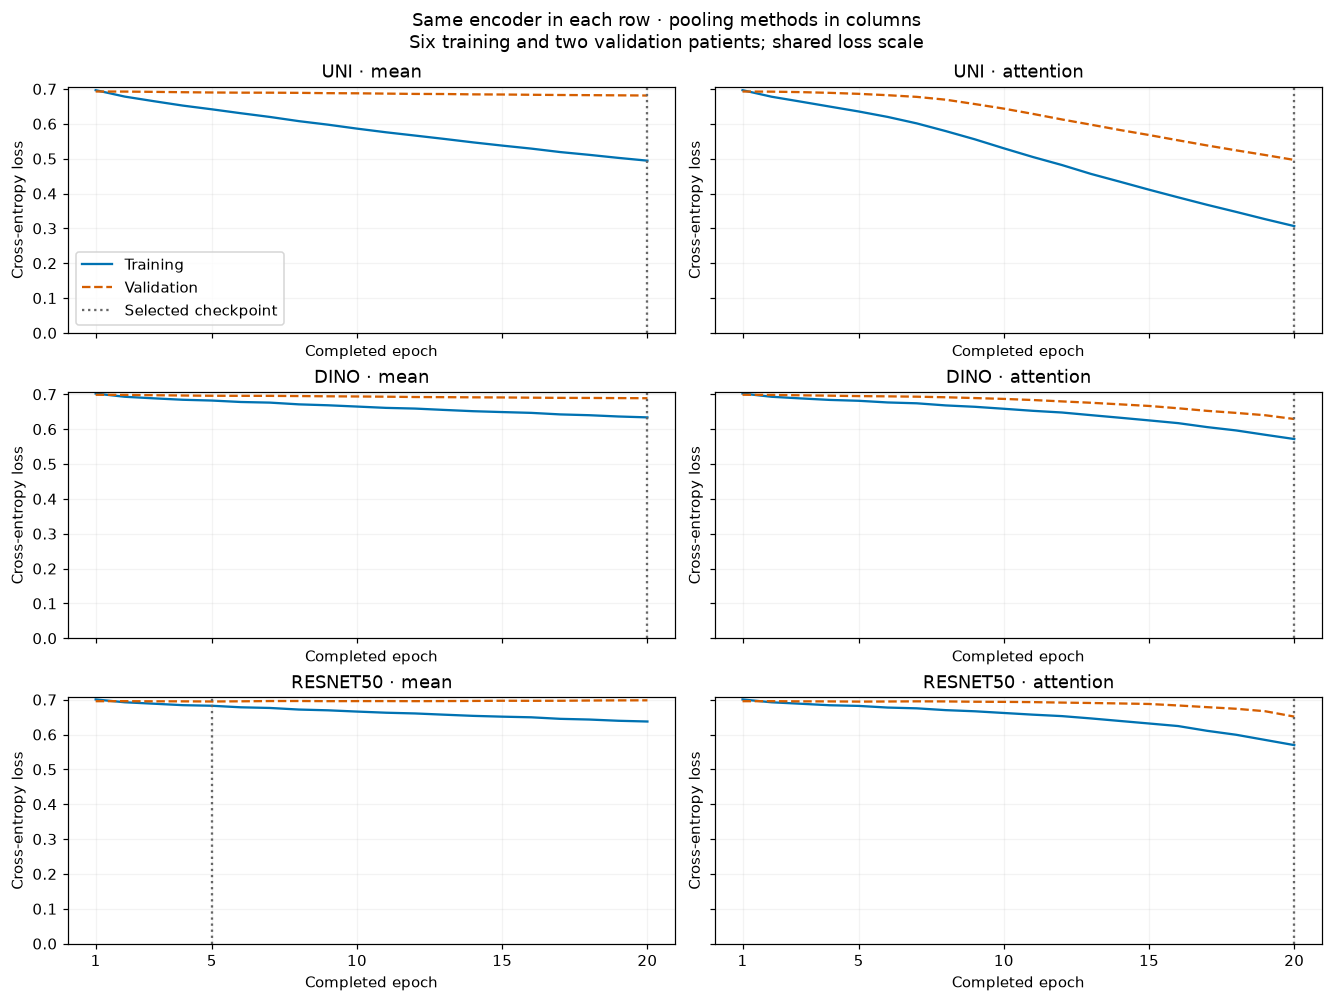

In [5]:
summary = pd.DataFrame([{
    'encoder': result['encoder_name'], 'classifier': result['pooling'],
    'selected_epoch': result['selected_epoch'], 'validation_loss': result['selected_val_loss'],
    'held_out_loss': result['test_loss'], 'held_out_accuracy': result['test_accuracy'],
    'correct_slides': sum(p['label'] == p['predicted_label'] for p in result['test_predictions']),
    'held_out_slides': len(result['test_predictions']), 'head_parameters': result['trainable_parameters'],
    'eligible_patches': sum(row['patches'] for row in result['inputs']),
} for result in comparison['results'].values()])
predictions = pd.DataFrame([{
    'encoder': result['encoder_name'], 'classifier': result['pooling'],
    'patient': p['patient_id'], 'diagnosis': CLASS_NAMES[p['label']],
    'prediction': CLASS_NAMES[p['predicted_label']], 'P(LUSC)': p['probabilities'][1],
} for result in comparison['results'].values() for p in result['test_predictions']])
summary.to_csv(OUT / 'model_comparison.csv', index=False)
predictions.to_csv(OUT / 'held_out_predictions.csv', index=False)

fig, axes = plt.subplots(len(settings['models']), 2, figsize=(12, 9),
                         sharex=True, sharey=True, layout='constrained', squeeze=False)
for row, encoder in enumerate(settings['models']):
    for col, pooling in enumerate(settings['poolings']):
        result = comparison['results'][f'{encoder}_{pooling}']
        history = result['history']
        ax = axes[row, col]
        for stage, label, color, style in [('train', 'Training', '#0072B2', '-'),
                                          ('val', 'Validation', '#D55E00', '--')]:
            ax.plot([h['epoch'] for h in history], [h[f'{stage}/loss'] for h in history],
                    label=label, color=color, linestyle=style)
        ax.axvline(result['selected_epoch'], color='0.4', linestyle=':', label='Selected checkpoint')
        ax.set_title(f'{encoder.upper()} · {pooling}')
        ax.set_ylim(bottom=0)
        ax.set_xlabel('Completed epoch')
        ax.set_xticks(np.unique(np.linspace(1, settings['epochs'], 5, dtype=int)))
        ax.set_ylabel('Cross-entropy loss')
        ax.grid(alpha=.15)
axes[0, 0].legend()
fig.suptitle('Same encoder in each row · pooling methods in columns\nSix training and two validation patients; shared loss scale')
fig.savefig(OUT / 'matched_learning_curves.png', dpi=130)
plt.show()

### 5a. Mean-pooling results

All patch embeddings have weight `1/N`. Only the slide-level linear classifier learns. This is a low-capacity baseline: useful minority regions can be diluted by abundant tissue, but it cannot overfit a learned patch-weighting function. Interpret its probabilities and errors as the outcome of this equal-weight assumption.

In [6]:
def display_classifier_results(pooling):
    table = summary.loc[summary['classifier'] == pooling].set_index('encoder')
    display(table.drop(columns='classifier').round(4))
    display(predictions.loc[predictions['classifier'] == pooling].drop(columns='classifier').round(4))
    observations = [
        f"**{encoder.upper()}**: {int(row.correct_slides)}/{int(row.held_out_slides)} correct; "
        f"held-out loss {row.held_out_loss:.3f}; selected epoch {int(row.selected_epoch)} "
        f"(validation loss {row.validation_loss:.3f})"
        for encoder, row in table.iterrows()
    ]
    display(Markdown('**Observed ' + pooling + ' results:** ' + '; '.join(observations) + '.'))
    if table['held_out_accuracy'].nunique() == 1:
        display(Markdown('Accuracy is tied across encoders for this classifier. Loss differences reflect '
                         'probabilities assigned to these two outcomes, not an established difference in generalization.'))
    else:
        display(Markdown('Accuracy differs on this held-out pair. One changed prediction moves accuracy by '
                         '50 percentage points, so this does not establish an encoder ranking.'))

    for encoder in settings['models']:
        result = comparison['results'][f'{encoder}_{pooling}']
        true_probabilities = [p['probabilities'][p['label']] for p in result['test_predictions']]
        if all(p['label'] == p['predicted_label'] for p in result['test_predictions']) and max(true_probabilities) < .55:
            shown = ', '.join(f'{p:.3f}' for p in true_probabilities)
            display(Markdown(f'**{encoder.upper()} caution:** both predictions are correct, but true-class '
                             f'probabilities are only {shown}. They barely cross the 0.5 decision boundary; '
                             'perfect accuracy on this pair conceals weak separation.'))
        errors = [p for p in result['test_predictions'] if p['label'] != p['predicted_label']]
        for p in errors:
            display(Markdown(f"**{encoder.upper()} error:** {p['patient_id']} is {CLASS_NAMES[p['label']]}, "
                             f"predicted {CLASS_NAMES[p['predicted_label']]}; true-class probability "
                             f"{p['probabilities'][p['label']]:.3f}."))

display_classifier_results('mean')

,selected_epoch,validation_loss,held_out_loss,held_out_accuracy,correct_slides,held_out_slides,head_parameters,eligible_patches
encoder,,,,,,,,
uni,20,0.6811,0.6217,1.0,2,2,2050,48621
dino,20,0.6887,0.6249,1.0,2,2,770,48621
resnet50,5,0.6947,0.6785,1.0,2,2,4098,48621


,encoder,patient,diagnosis,prediction,P(LUSC)
0,uni,TCGA-38-7271,LUAD,LUAD,0.4728
1,uni,TCGA-85-7698,LUSC,LUSC,0.5470
4,dino,TCGA-38-7271,LUAD,LUAD,0.4634
5,dino,TCGA-85-7698,LUSC,LUSC,0.5340
8,resnet50,TCGA-38-7271,LUAD,LUAD,0.4953
9,resnet50,TCGA-85-7698,LUSC,LUSC,0.5101


**Observed mean results:** **UNI**: 2/2 correct; held-out loss 0.622; selected epoch 20 (validation loss 0.681); **DINO**: 2/2 correct; held-out loss 0.625; selected epoch 20 (validation loss 0.689); **RESNET50**: 2/2 correct; held-out loss 0.678; selected epoch 5 (validation loss 0.695).

Accuracy is tied across encoders for this classifier. Loss differences reflect probabilities assigned to these two outcomes, not an established difference in generalization.

**UNI caution:** both predictions are correct, but true-class probabilities are only 0.527, 0.547. They barely cross the 0.5 decision boundary; perfect accuracy on this pair conceals weak separation.

**DINO caution:** both predictions are correct, but true-class probabilities are only 0.537, 0.534. They barely cross the 0.5 decision boundary; perfect accuracy on this pair conceals weak separation.

**RESNET50 caution:** both predictions are correct, but true-class probabilities are only 0.505, 0.510. They barely cross the 0.5 decision boundary; perfect accuracy on this pair conceals weak separation.

### 5b. Attention-MIL results

The attention network and linear classifier learn together from slide labels. Pooling can emphasize selected patterns, but six training patients give little evidence that those patterns are disease-specific rather than artefacts, preparation or sampling differences. An attractive attention map is not validation of the classifier.

In [7]:
display_classifier_results('attention')

,selected_epoch,validation_loss,held_out_loss,held_out_accuracy,correct_slides,held_out_slides,head_parameters,eligible_patches
encoder,,,,,,,,
uni,20,0.4963,0.5095,1.0,2,2,133379,48621
dino,20,0.6291,0.5899,1.0,2,2,50179,48621
resnet50,20,0.6513,0.6053,0.5,1,2,266499,48621


,encoder,patient,diagnosis,prediction,P(LUSC)
2,uni,TCGA-38-7271,LUAD,LUAD,0.4434
3,uni,TCGA-85-7698,LUSC,LUSC,0.6485
6,dino,TCGA-38-7271,LUAD,LUAD,0.4383
7,dino,TCGA-85-7698,LUSC,LUSC,0.5472
10,resnet50,TCGA-38-7271,LUAD,LUAD,0.3826
11,resnet50,TCGA-85-7698,LUSC,LUAD,0.4827


**Observed attention results:** **UNI**: 2/2 correct; held-out loss 0.509; selected epoch 20 (validation loss 0.496); **DINO**: 2/2 correct; held-out loss 0.590; selected epoch 20 (validation loss 0.629); **RESNET50**: 1/2 correct; held-out loss 0.605; selected epoch 20 (validation loss 0.651).

Accuracy differs on this held-out pair. One changed prediction moves accuracy by 50 percentage points, so this does not establish an encoder ranking.

**RESNET50 error:** TCGA-85-7698 is LUSC, predicted LUAD; true-class probability 0.483.

### 5c. Compare the two classifiers within each encoder

Accuracy on two held-out slides can only be 0, 0.5 or 1.0. Cross-entropy also reflects confidence, but these two outcomes cannot establish calibration, robustness or superiority. No multi-seed uncertainty estimate or independent-cohort evaluation is claimed.

In [8]:
display(summary.pivot(index='encoder', columns='classifier',
                      values=['held_out_accuracy', 'held_out_loss']).round(4))
display(Markdown('Read the pooling contrast **within each encoder**. Attention has extra trainable '
                 'parameters, while mean pooling fixes equal patch weights. Differences may reflect '
                 'optimization and this split; lower loss or a sharper map does not prove better tissue recognition.'))
for encoder in settings['models']:
    mean = comparison['results'][f'{encoder}_mean']
    attention = comparison['results'][f'{encoder}_attention']
    if attention['test_loss'] < mean['test_loss'] and attention['test_accuracy'] < mean['test_accuracy']:
        paired = []
        for left, right in zip(mean['test_predictions'], attention['test_predictions'], strict=True):
            assert left['patient_id'] == right['patient_id'] and left['label'] == right['label']
            label = left['label']
            paired.append(f"{CLASS_NAMES[label]} true-class probability "
                          f"{left['probabilities'][label]:.3f} → {right['probabilities'][label]:.3f}")
        display(Markdown(f"**Why {encoder.upper()} has lower attention loss but worse accuracy:** "
                         + '; '.join(paired) + '. Cross-entropy averages the negative log true-class '
                         'probabilities; accuracy only checks which side of the decision boundary each '
                         'prediction falls. Here, one confidence gain outweighs the other loss in average '
                         'cross-entropy, even though one label flips incorrectly.'))


held_out_accuracy      held_out_loss        
classifier         attention mean     attention    mean
encoder                                                
dino                     1.0  1.0        0.5899  0.6249
resnet50                 0.5  1.0        0.6053  0.6785
uni                      1.0  1.0        0.5095  0.6217

Read the pooling contrast **within each encoder**. Attention has extra trainable parameters, while mean pooling fixes equal patch weights. Differences may reflect optimization and this split; lower loss or a sharper map does not prove better tissue recognition.

**Why RESNET50 has lower attention loss but worse accuracy:** LUAD true-class probability 0.505 → 0.617; LUSC true-class probability 0.510 → 0.483. Cross-entropy averages the negative log true-class probabilities; accuracy only checks which side of the decision boundary each prediction falls. Here, one confidence gain outweighs the other loss in average cross-entropy, even though one label flips incorrectly.

## 6. Interpret each classifier separately

**Mean pooling:** the signed contribution of patch `i` to class `c` is `(w_c · h_i) / N`; summing all contributions and adding the classifier bias recovers that class logit. Positive and negative values raise or lower the chosen logit. They are not probabilities or causal tissue effects, and a single-class contribution is not the two-class decision margin.

**Attention MIL:** maps show learned pooling-weight percentiles within a slide. High attention means the model gives an embedding more weight; it does not specify whether that patch supports LUAD or LUSC. These maps are not calibrated tumour probabilities, cell annotations or transformer self-attention.

The class-specific views explain the **LUSC logit**. The whole-slide comparison uses **TCGA-85-7698**, an existing held-out LUSC slide with one main tissue section and small peripheral fragments, selected for its layout rather than its prediction. Prominent pen marks remain visible: inspect whether emphasized regions follow tissue morphology or artefacts. Both held-out slides have exported explanations. Mean contribution values and attention percentiles have different units and must not be compared as magnitudes.

**Which axis is attended?** The MIL input is `[N patches, D features]`. The scoring network returns `[N, 1]`, and softmax normalizes across **N patches**. `attention_dim=128` is its hidden width, not a feature-attention axis. One scalar weights each entire patch embedding. The spatial overlay is therefore a between-patch map; it cannot locate structures inside a patch.

For a pathology-specific interpretation reference, see [Lu et al., *Data-efficient and weakly supervised computational pathology on whole-slide images* (CLAM, 2021)](https://www.nature.com/articles/s41551-020-00682-w). The study compared attention heatmaps with pathologist tumour annotations. Such maps can direct review to candidate regions and help assess whether emphasized tissue contains plausible morphology or artefacts. Their value comes from that inspection and validation, not from treating high weights as tumour probability or causality. Our simple attention head does not reproduce CLAM's clustering-constrained classifier.

**ResNet with a custom head:** the loader replaces ResNet-50's ImageNet `fc` with `Identity`, yielding 2,048-dimensional patch embeddings. The demo freezes that encoder and trains a new two-class linear head after mean or learned attention pooling. Its MIL weights are spatial patch weights even though the ResNet backbone itself has no transformer attention.

Each encoder uses the same whole-slide thumbnail: original RGB, signed mean-pooling contributions, and learned attention-MIL percentiles. All eligible coordinates participate; unscored background stays uncoloured. The main comparison uses no numbered patch markers or patch-grid zooms.

All three models appear in one comparison figure. Signed mean-contribution colour limits are computed separately for each encoder; use the colourbars to read values. MIL colours show within-slide ranks, so equal colours across encoders do not imply equal raw pooling weights.

Same held-out slide: 5048c79f-ed1d-4534-8da2-1a4d207b2371 · common explanation target: LUSC


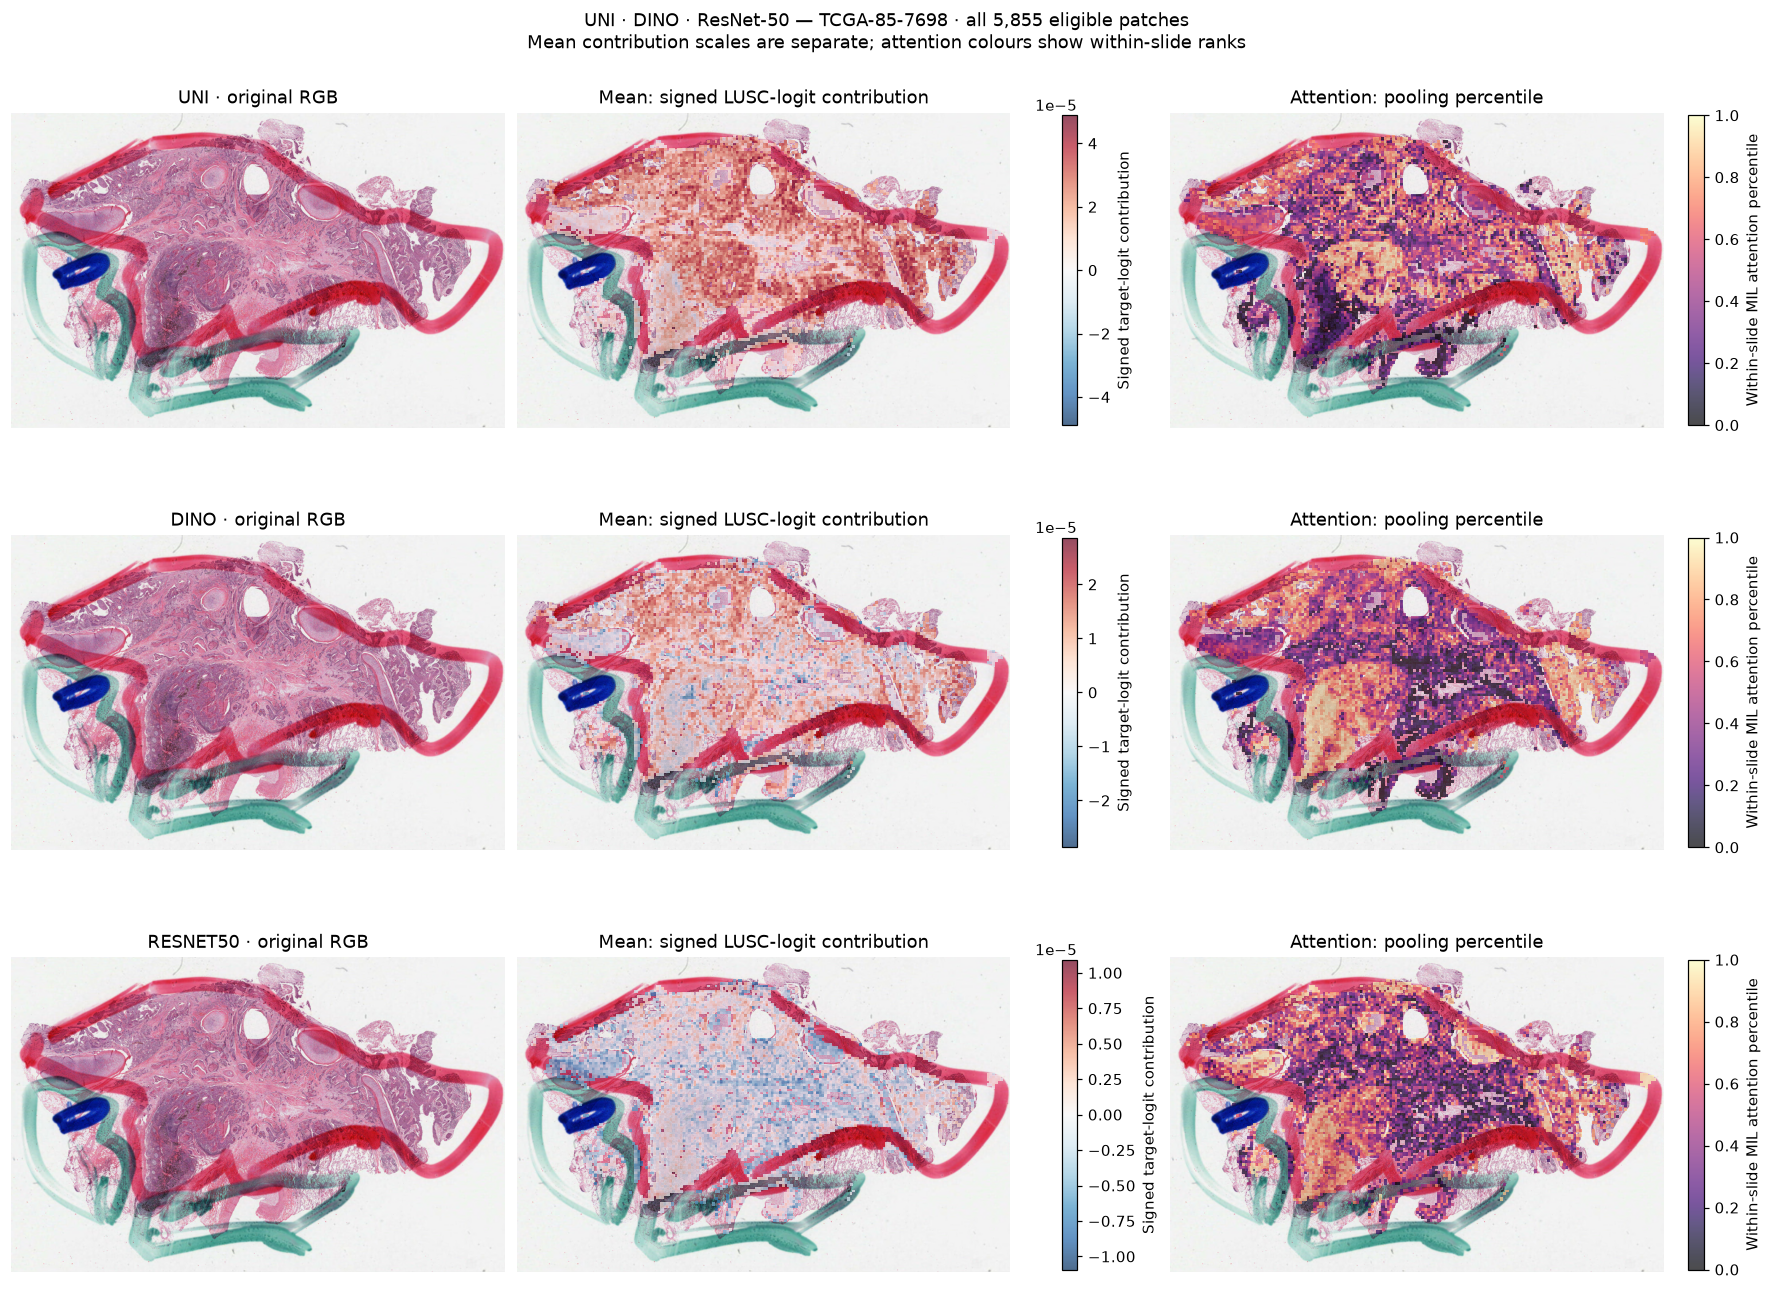

In [9]:
import openslide
from src.interpretation.mil import plot_slide_scores

# Choose a held-out slide with one main tissue section, independently of model scores.
DISPLAY_PATIENT = 'TCGA-85-7698'
DISPLAY_SLIDE = next(row['bag_id'] for row in rows
                     if row['split'] == 'test' and row['group_id'] == DISPLAY_PATIENT)
TARGET_CLASS = CLASS_NAMES[settings['interpretation_class_index']]
item = next(i for i in items if i['row']['bag_id'] == DISPLAY_SLIDE)
with openslide.OpenSlide(item['row']['wsi_path']) as slide:
    thumbnail = slide.get_thumbnail((1200, 1200)).convert('RGB')
print('Same held-out slide:', DISPLAY_SLIDE, '· common explanation target:', TARGET_CLASS)
fig, grid = plt.subplots(len(settings['models']), 3, figsize=(16, 12),
                         layout='constrained', squeeze=False)
slide_coords = None
for model_row, encoder in enumerate(settings['models']):
    axes = grid[model_row]
    axes[0].imshow(thumbnail)
    axes[0].set_title(f'{encoder.upper()} · original RGB')
    axes[0].axis('off')
    for ax, pooling in zip(axes[1:], settings['poolings'], strict=True):
        kind = 'contribution' if pooling == 'mean' else 'attention'
        filename = 'slide_contributions.npz' if pooling == 'mean' else 'slide_attention.npz'
        folder = OUT / 'comparison' / f'{encoder}_{pooling}' / 'interpretation' / DISPLAY_SLIDE
        title = f'Mean: signed {TARGET_CLASS}-logit contribution' if pooling == 'mean' else 'Attention: pooling percentile'
        with np.load(folder / filename) as values:
            if slide_coords is None:
                slide_coords = values['coords'].copy()
            assert np.array_equal(slide_coords, values['coords'])
            plot_slide_scores(thumbnail, item['selection']['dimensions'], values['coords'],
                              item['selection']['source_size'], values['scores'],
                              title=title, score_kind=kind, ax=ax)
fig.suptitle(f'UNI · DINO · ResNet-50 — {item["row"]["group_id"]} · all {item["eligible_patches"]:,} eligible patches\n'
             'Mean contribution scales are separate; attention colours show within-slide ranks')
fig.savefig(OUT / 'three_model_pooling_maps.png', dpi=130)
plt.show()


### Within-patch localization across three models

[HIPT (Chen et al., CVPR 2022)](https://openaccess.thecvf.com/content/CVPR2022/html/Chen_Scaling_Vision_Transformers_to_Gigapixel_Images_via_Hierarchical_Self-Supervised_Learning_CVPR_2022_paper.html) and its [visualisation code](https://github.com/mahmoodlab/HIPT/blob/780fafaed2e5b112bc1ed6e78852af1fe6714342/HIPT_4K/attention_visualization_utils.py#L249-L349) motivate the selective attention overlay below. These are **UNI/DINO encoder maps**, not a HIPT model or a 4K hierarchy.

The extractor reads the actual final transformer's attention matrix: **CLS query → spatial key tokens**, averaged over heads. In this demo, the 224×224 model input has a **14×14 grid of 16-pixel tokens**. It attends over image positions, not embedding channels. This encoder self-attention is class-agnostic and identical for the two frozen-encoder classifier variants, so it is shown once per patch. ResNet uses the explicitly labelled class-specific Grad-CAM columns described below; its MIL attention remains available in the preceding whole-slide maps.

**Amber tiles with cyan outlines** highlight tokens at or above the within-patch 80th percentile (`patch_attention_percentile: 0.8`). This is a display choice, not a tissue threshold or a cumulative attention-mass cutoff. The raw per-head scores are saved; nearest-neighbour expansion preserves the token grid. No patch pixels are shifted, padded or inpainted for inference. Head averaging and percentile highlighting can conceal differences in absolute attention strength, and highlighted regions are not cell segmentations.

Each row uses the same RGB patch across all three models. The combined localization figure places UNI/DINO encoder attention beside both ResNet Grad-CAM heads; it compares spatial patterns from different methods, not a common attribution score. The following input-gradient figures compare the same sensitivity method across all three models, separately for mean and attention pooling. First, middle and last coordinate positions are deterministic examples, not importance-ranked or representative tissue samples. Together, these views help distinguish encoder spatial associations, learned slide weighting and class-score sensitivity; none alone establishes biological relevance.

**ResNet Grad-CAM:** following [Selvaraju et al. (ICCV 2017)](https://openaccess.thecvf.com/content_iccv_2017/html/Selvaraju_Grad-CAM_Visual_Explanations_ICCV_2017_paper.html), gradients of the **trained head's LUSC logit** weight the final `layer4` convolutional maps. Positive Grad-CAM values use the same **magma** palette as the whole-slide attention maps, separately for mean and attention pooling. Dark purple indicates weaker positive values; orange/yellow indicates stronger values. The scale is `max(raw CAM, 0) / max(positive CAM)` within each panel: **1 is that panel's maximum, not a probability**. Zero-valued regions retain their original RGB; negative values are omitted by ReLU. Equal colours across panels do not imply equal absolute support, and these values are not attention percentiles. The original 7×7 map is expanded with nearest-neighbour interpolation, so blocks reflect coarse feature resolution. Other patch embeddings remain fixed; the custom slide head is part of the gradient path. This is **not** the discarded ImageNet classifier and is not transformer attention. An all-zero positive map is reported without inventing a hotspot. The shared palette changes presentation only: Grad-CAM remains class-conditioned localization, whereas MIL attention expresses between-patch pooling weights. The values are not comparable causal effects.

**QC negative example (third row): red pen on glass.** The patch at level-0 `(x=92076, y=23066)` lies on the external red marker loop of TCGA-85-7698, beyond the tissue edge; its larger WSI context was visually checked. It is an ink-dominated region without interpretable cellular morphology, not an example of blurred tissue. It passed the cached CLAM-saturation eligibility mask used for this classification run.

All three pretrained encoders still produce features and visual responses for this input. Original UNI is a pathology foundation model, but its pretraining does not replace tissue selection and artefact QC. Keep this row to inspect how non-tissue can enter the classifier and receive pooling weight. A highlighted token or bright independently scaled Grad-CAM/gradient panel does not establish useful tissue evidence. The table below reports the actual learned attention weights; this is not a paired QC-on/QC-off experiment or a measured improvement in classification accuracy.


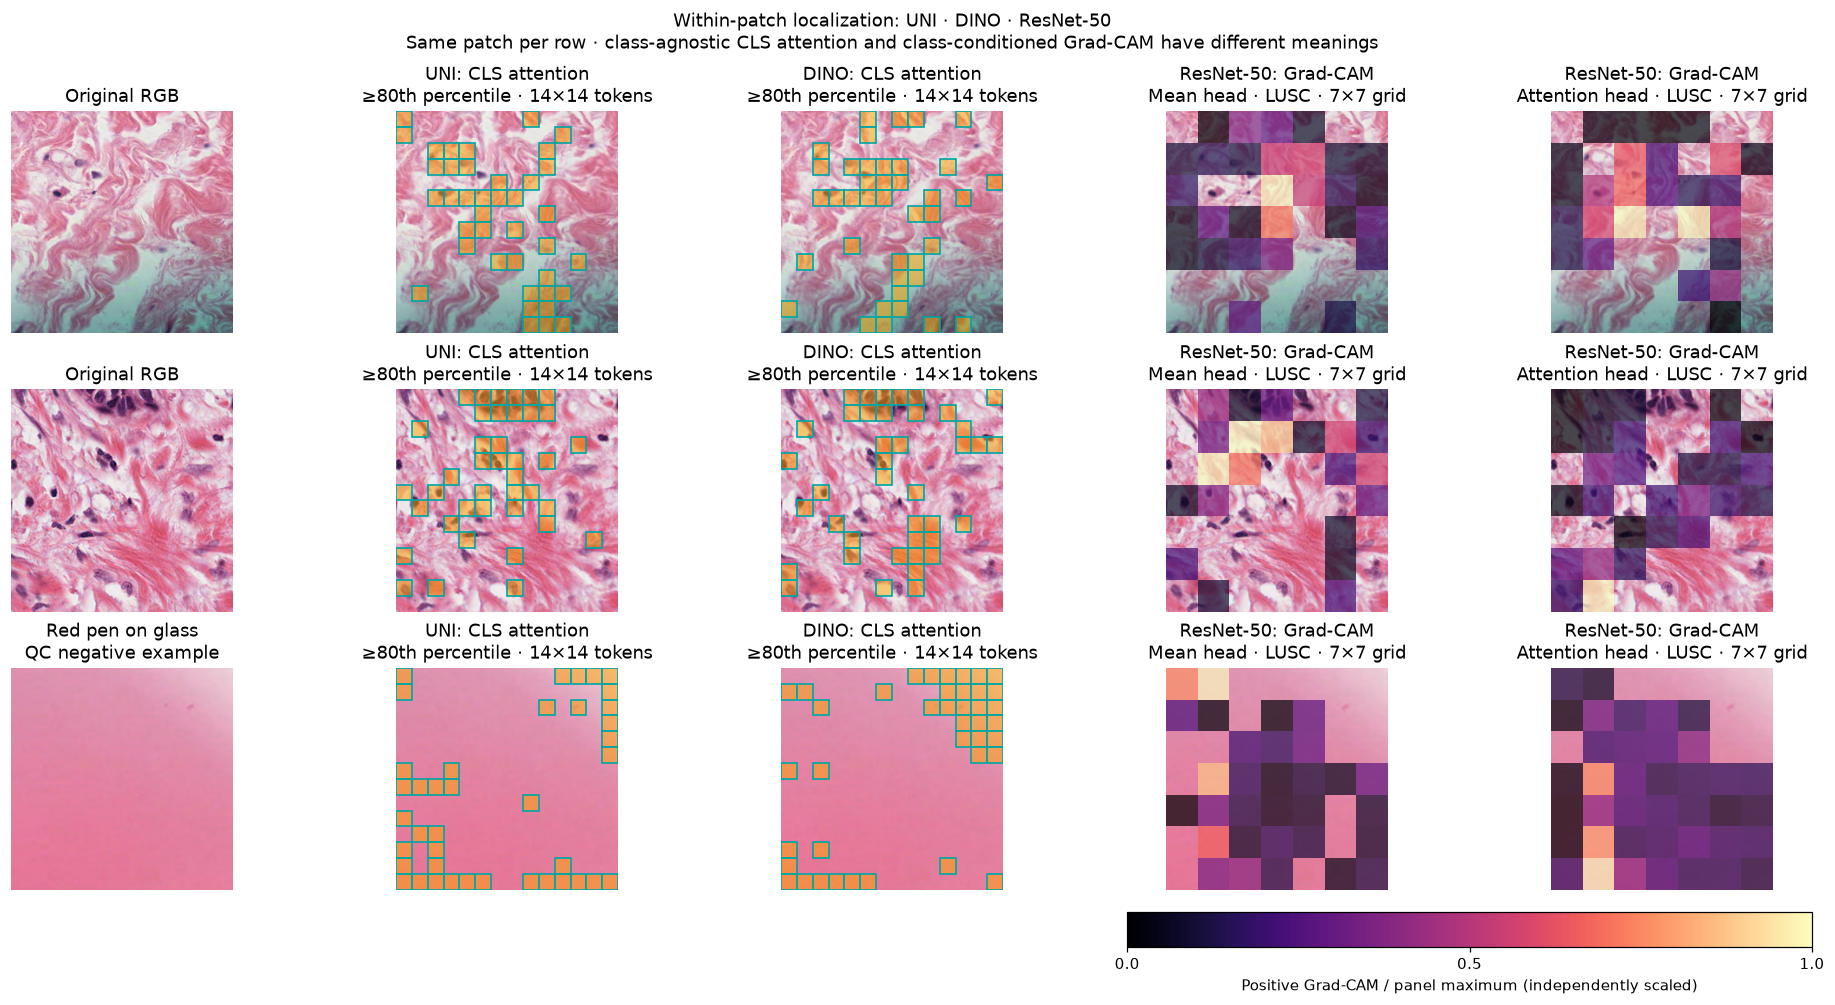

In [10]:
from matplotlib.patches import Rectangle
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

MODEL_LABELS = {'uni': 'UNI', 'dino': 'DINO', 'resnet50': 'ResNet-50'}
assert set(settings['models']) == set(MODEL_LABELS), 'This comparison requires all three encoders.'
patch_records, patch_arrays = {}, {}
chosen = None
for encoder in settings['models']:
    for pooling in settings['poolings']:
        folder = OUT / 'comparison' / f'{encoder}_{pooling}' / 'interpretation' / DISPLAY_SLIDE
        record = json.loads((folder / 'interpretation.json').read_text())
        indices = [p['index'] for p in record['patches']]
        if chosen is None:
            chosen = indices
        assert indices == chosen and record['target_class'] == TARGET_CLASS
        patch_records[encoder, pooling] = {p['index']: p for p in record['patches']}
        for index in chosen:
            with np.load(folder / f'patch_{index}.npz') as saved:
                patch_arrays[encoder, pooling, index] = {k: saved[k] for k in saved.files}

# Compare identical image bytes and coordinates across all six fitted classifiers.
for index in chosen:
    reference = patch_arrays[settings['models'][0], 'mean', index]
    for encoder in settings['models']:
        for pooling in settings['poolings']:
            values = patch_arrays[encoder, pooling, index]
            assert np.array_equal(values['rgb'], reference['rgb'])
            assert np.array_equal(values['xy'], reference['xy'])

# This coordinate was checked in a larger source-WSI context: red pen on glass.
QC_NEGATIVE_XY = np.array([92076, 23066])
qc_indices = [i for i in chosen if np.array_equal(patch_arrays['uni', 'mean', i]['xy'], QC_NEGATIVE_XY)]
assert DISPLAY_PATIENT == 'TCGA-85-7698' and len(qc_indices) == 1
QC_NEGATIVE_INDEX = qc_indices[0]

fig, axes = plt.subplots(len(chosen), 5, figsize=(17.5, 9), layout='constrained', squeeze=False)
for row, index in enumerate(chosen):
    rgb = patch_arrays['uni', 'mean', index]['rgb']
    axes[row, 0].imshow(rgb)
    axes[row, 0].set_title('Red pen on glass\nQC negative example' if index == QC_NEGATIVE_INDEX else 'Original RGB')
    for col, encoder in enumerate(('uni', 'dino'), start=1):
        record = next(p for p in comparison['encoder_attention'][encoder][DISPLAY_SLIDE]['patches']
                      if p['index'] == index)
        assert record['status'] == 'available'
        assert hashlib.sha256(rgb.tobytes(order='C')).hexdigest() == record['source_rgb_sha256']
        with np.load(record['file']) as saved:
            assert np.array_equal(saved['xy'], patch_arrays[encoder, 'mean', index]['xy'])
            selected = saved['percentile_attention'] >= record['threshold_percentile']
        height, width = record['model_input_shape']
        axes[row, col].imshow(Image.fromarray(rgb).resize((width, height), Image.Resampling.BILINEAR))
        token_height, token_width = height / selected.shape[0], width / selected.shape[1]
        for y, x in np.argwhere(selected):
            axes[row, col].add_patch(Rectangle(
                (x * token_width - .5, y * token_height - .5), token_width, token_height,
                facecolor=(1, .65, 0, .5), edgecolor='#00A6A6', linewidth=1.1))
        cutoff = 100 * record['threshold_percentile']
        axes[row, col].set_title(f'{MODEL_LABELS[encoder]}: CLS attention\n≥{cutoff:.0f}th percentile · 14×14 tokens')
    for col, pooling in enumerate(settings['poolings'], start=3):
        cam = patch_arrays['resnet50', pooling, index]['gradcam_display']
        record = patch_records['resnet50', pooling][index]['gradcam']
        height, width = record['model_input_shape']
        axes[row, col].imshow(Image.fromarray(rgb).resize((width, height), Image.Resampling.BILINEAR))
        if record['has_positive_support']:
            axes[row, col].imshow(np.ma.masked_where(cam <= 0, cam), cmap='magma',
                                 vmin=0, vmax=1, alpha=.7, interpolation='nearest')
            detail = f'{pooling.capitalize()} head · {TARGET_CLASS} · 7×7 grid'
        else:
            detail = f'{pooling.capitalize()} head · no positive support'
        axes[row, col].set_title(f'ResNet-50: Grad-CAM\n{detail}')
    for ax in axes[row]:
        ax.axis('off')
fig.colorbar(ScalarMappable(norm=Normalize(0, 1), cmap='magma'),
             ax=axes[:, 3:5].ravel().tolist(), location='bottom', shrink=.9, pad=.025,
             ticks=[0, .5, 1], label='Positive Grad-CAM / panel maximum (independently scaled)')
fig.suptitle('Within-patch localization: UNI · DINO · ResNet-50\n'
             'Same patch per row · class-agnostic CLS attention and class-conditioned Grad-CAM have different meanings')
fig.savefig(OUT / 'three_model_patch_localization.png', dpi=130)
plt.show()


### Matched input-gradient comparisons

Each figure compares **UNI, DINO and ResNet-50** for one pooling method. Every row uses exactly the same patch bytes and coordinates. Grayscale shows absolute input-gradient sensitivity of the same LUSC slide logit; the printed 99th-percentile scale is fitted separately for each panel, so brightness compares spatial patterns rather than absolute sensitivity across models. Other patch embeddings stay fixed, and MIL pooling is recomputed over the complete bag.

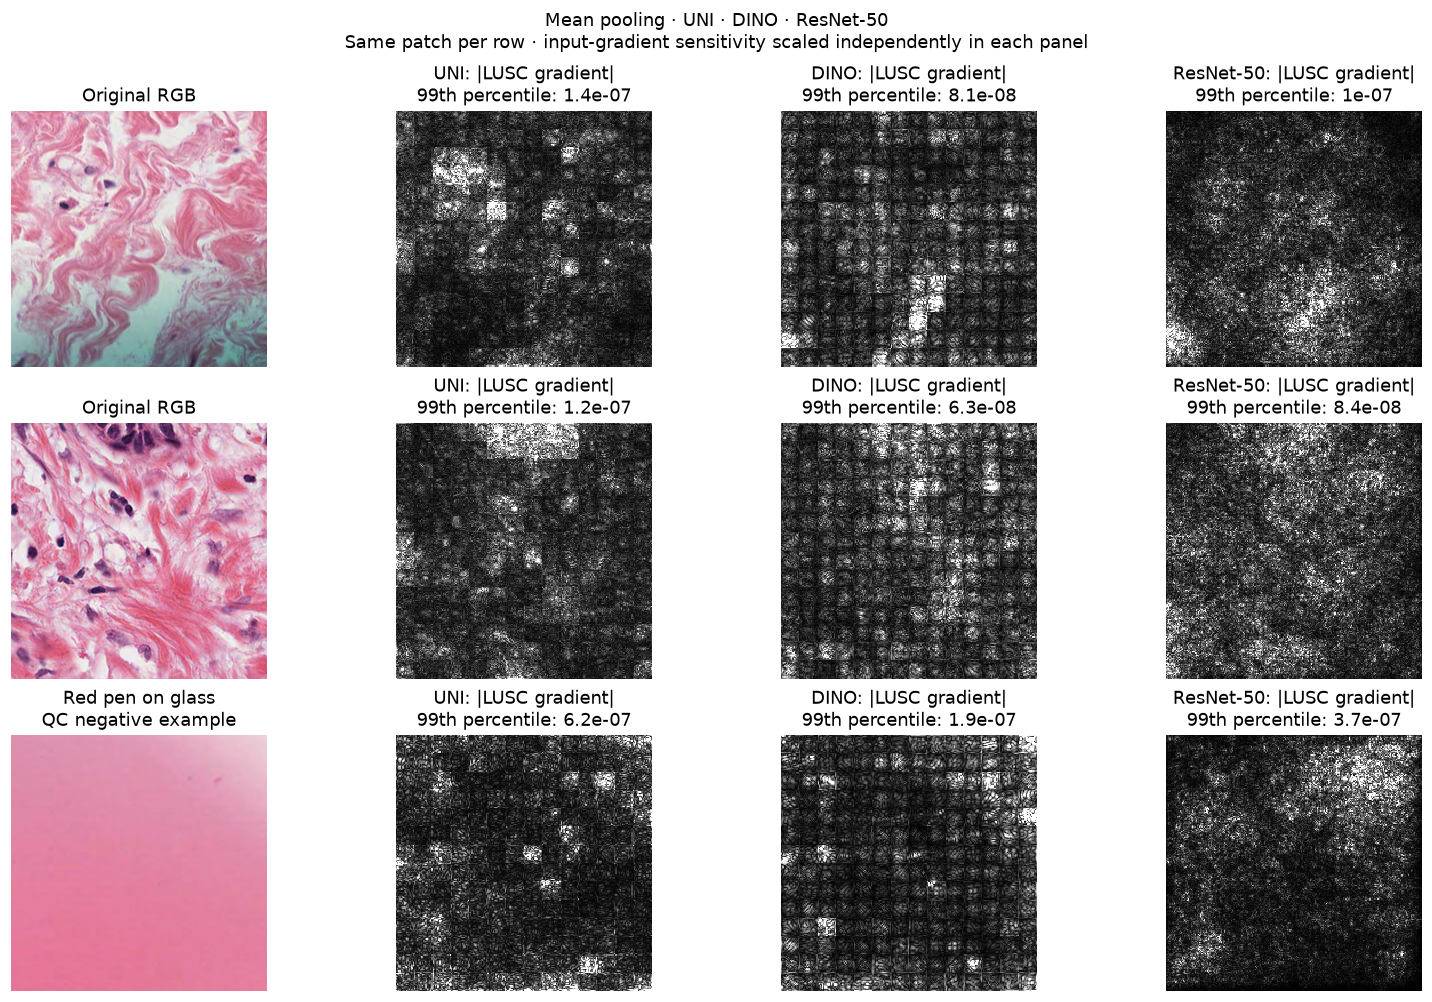

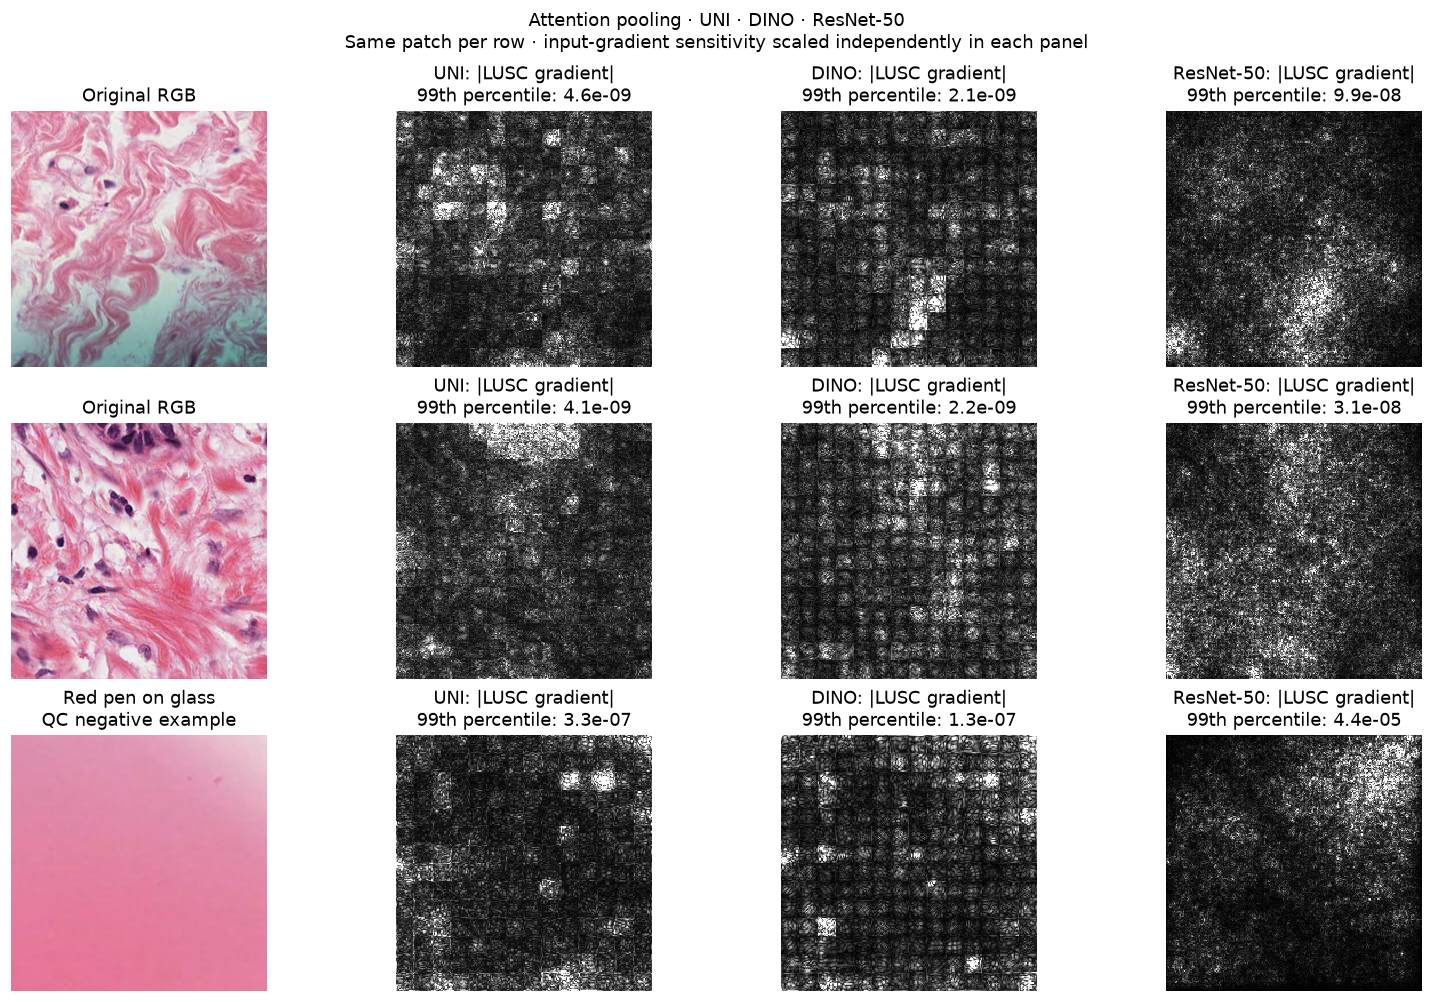

In [11]:
for pooling in settings['poolings']:
    fig, axes = plt.subplots(len(chosen), 4, figsize=(14, 9), layout='constrained', squeeze=False)
    for row, index in enumerate(chosen):
        axes[row, 0].imshow(patch_arrays[settings['models'][0], pooling, index]['rgb'])
        axes[row, 0].set_title('Red pen on glass\nQC negative example' if index == QC_NEGATIVE_INDEX else 'Original RGB')
        for col, encoder in enumerate(settings['models'], start=1):
            gradient = patch_arrays[encoder, pooling, index]['saliency']
            scale = float(np.quantile(gradient, .99))
            shown = np.clip(gradient / scale, 0, 1) if scale > 0 else np.zeros_like(gradient)
            axes[row, col].imshow(shown, cmap='gray', vmin=0, vmax=1, interpolation='nearest')
            axes[row, col].set_title(f'{MODEL_LABELS[encoder]}: |{TARGET_CLASS} gradient|\n99th percentile: {scale:.2g}')
        for ax in axes[row]:
            ax.axis('off')
    fig.suptitle(f'{pooling.capitalize()} pooling · UNI · DINO · ResNet-50\n'
                 'Same patch per row · input-gradient sensitivity scaled independently in each panel')
    fig.savefig(OUT / f'three_model_{pooling}_gradients.png', dpi=130)
    plt.show()


### How the QC negative example enters each model's pooling

The same red-pen patch is included in each complete slide bag. Mean pooling gives every patch weight `1/N`; attention pooling learns its weights. The within-slide percentile describes rank, while the ratio to `1/N` compares this patch with equal weighting. These values show how each fitted head handles this artefact; they are not tissue probabilities, causal effects or an encoder quality ranking.

In [12]:
from scipy.stats import rankdata

qc_rows = []
for encoder in settings['models']:
    folder = OUT / 'comparison' / f'{encoder}_attention' / 'interpretation' / DISPLAY_SLIDE
    with np.load(folder / 'slide_attention.npz') as saved:
        assert np.array_equal(saved['coords'][QC_NEGATIVE_INDEX], QC_NEGATIVE_XY)
        weights = saved['weights']
        weight = float(weights[QC_NEGATIVE_INDEX])
        percentile = 100 * rankdata(weights, method='average')[QC_NEGATIVE_INDEX] / len(weights)
        qc_rows.append({'encoder': MODEL_LABELS[encoder], 'mean_pooling_weight': 1 / len(weights),
                        'attention_weight': weight, 'within_slide_percentile': percentile,
                        'attention_vs_equal_weight': weight * len(weights)})
qc_comparison = pd.DataFrame(qc_rows).set_index('encoder')
qc_comparison.to_csv(OUT / 'qc_negative_example.csv')
display(qc_comparison.style.format({'mean_pooling_weight': '{:.6f}', 'attention_weight': '{:.6f}',
                                  'within_slide_percentile': '{:.2f}', 'attention_vs_equal_weight': '{:.2f}×'}))
display(Markdown('Inspect this table alongside the **red-pen negative row**. The encoder attention and '
                 'saliency displays are independently scaled; visible highlights can coexist with low pooling weight. '
                 'Preprocessing and QC determine whether such non-tissue should enter the bag in the first place.'))


,mean_pooling_weight,attention_weight,within_slide_percentile,attention_vs_equal_weight
encoder,,,,
UNI,0.000171,0.000016,65.47,0.10×
DINO,0.000171,0.000051,51.94,0.30×
ResNet-50,0.000171,0.004233,99.88,24.78×


Inspect this table alongside the **red-pen negative row**. The encoder attention and saliency displays are independently scaled; visible highlights can coexist with low pooling weight. Preprocessing and QC determine whether such non-tissue should enter the bag in the first place.

## 7. Evidence and limits

The receipt records complete feature-cache coverage, model hashes, patient splits, optimization history, selected checkpoints and interpretation targets. Frozen features from test slides are computed without labels; training and checkpoint selection use only their declared splits. Existing tissue eligibility is a preprocessing decision, not a tumour annotation.


In [13]:
for source in source_state.values():
    current = Path(source['path']).stat()
    assert (current.st_size, current.st_mtime_ns) == (source['size_bytes'], source['mtime_ns'])
    assert sha256(source['coords_path']) == source['coords_sha256']
receipt = {'status': 'complete', 'split_manifest': str(manifest), 'split_sha256': sha256(manifest),
    'preprocessing_manifest': str(preprocessing_manifest_path), 'preprocessing_sha256': sha256(preprocessing_manifest_path),
    'source_files': source_state, 'same_patient_split_across_models': True,
    'models': comparison['models'], 'poolings': comparison['poolings'], 'comparisons': comparison['comparisons'],
    'all_eligible_patches_per_encoder': int(coverage['eligible_patches'].sum()),
    'comparison_receipt': str(OUT / 'comparison/comparison_receipt.json'),
    'elapsed_seconds': time.monotonic() - started,
    'interpretation': 'Frozen encoders plus trained slide classifiers; ten-patient teaching comparison'}
(OUT / 'run_receipt.json').write_text(json.dumps(receipt, indent=2, allow_nan=False))
print('Outputs:', OUT)

Outputs: /Users/irina/Projects/digital-pathology-demo/outputs/wsi_classification_demo/20261103T231255Z_81ba9fd6


## Pretrained model provenance

| Exact encoder | Training strategy before this demo | Pretraining data |
| --- | --- | --- |
| **Original UNI**, ViT-L/16 (`MahmoodLab/UNI`, not UNI2) | DINOv2 self-supervision: multi-crop teacher/student self-distillation, an iBOT masked-image objective and KoLeo regularization. | **Mass-100K**: approximately 100 million H&E patches from more than 100,000 WSIs across 20 organs, sourced from BWH, MGH and GTEx. [Model card](https://huggingface.co/MahmoodLab/UNI), [paper](https://www.nature.com/articles/s41591-024-02857-3). |
| **DINO ViT-S/16** (`timm/vit_small_patch16_224.dino`) | Self-supervised multi-crop teacher/student distillation without diagnosis or ImageNet class labels. | **ImageNet-1k** images. [Exact model card](https://huggingface.co/timm/vit_small_patch16_224.dino), [DINO paper](https://arxiv.org/abs/2104.14294). |
| **ResNet-50 IMAGENET1K_V2** (`resnet50-11ad3fa6.pth`) | Supervised 1,000-class classification with TorchVision's improved training recipe. | **ImageNet-1k**. [Official weights and recipe](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet50.html). |

This demo freezes each encoder and trains either the mean-pooled linear classification head or the attention-pooling/classification head on the declared TCGA-LUAD/LUSC training patients. Validation selects the checkpoint; held-out labels do not enter training. Pretraining provenance describes initialization, not generalization or a guarantee of disease-specific representations.
